# Tarea Semanal 7
## Teoría de Circuitos II
## Alumno
### Juan Manuel Miranda Del Valle
## Institución
### Universidad Tecnologica Nacional
## Profesores
### Mariano Llamedo Soria y César Fouco
## Consignas

<div align="center">
    <img src="1.png" width="1000">
</div>

# 1) Obtención de la función transferencia
<div align="center">
    <img src="2.png" width="1000">
</div>

Definimos la señal a la salida del **Comb** como:

$$
X_2(z)=X(z)-X(z)z^{-N}c_1
$$

Por lo tanto:

$$
\boxed{X_2(z)=X(z)\left(1-c_1z^{-N}\right)}
$$

y entonces:

$$
\frac{X_2(z)}{X(z)}=1-c_1z^{-N}
$$

---

## Red recursiva de segundo orden

Para la señal interna $W(z)$:

$$
W(z)=a_0X_2(z)+a_0a_1W(z)z^{-1}+a_0a_2W(z)z^{-2}
$$

Reordenando:

$$
a_0X_2(z)
=
W(z)-a_0a_1W(z)z^{-1}-a_0a_2W(z)z^{-2}
$$

Dividiendo por $a_0$:

$$
X_2(z)
=
W(z)
\left(
\frac{1}{a_0}-a_1z^{-1}-a_2z^{-2}
\right)
$$

Entonces:

$$
\boxed{
\frac{W(z)}{X_2(z)}
=
\frac{1}
{\frac{1}{a_0}-a_1z^{-1}-a_2z^{-2}}
}
$$

---

## Salida de la red

La salida viene dada por:

$$
Y(z)=b_0W(z)+b_1W(z)z^{-1}+b_2W(z)z^{-2}
$$

Por lo tanto:

$$
\boxed{
\frac{Y(z)}{W(z)}
=
b_0+b_1z^{-1}+b_2z^{-2}
}
$$

---

## Función transferencia total

La transferencia total puede escribirse como:

$$
\frac{Y(z)}{X(z)}
=
\frac{X_2(z)}{X(z)}
\frac{W(z)}{X_2(z)}
\frac{Y(z)}{W(z)}
$$

Entonces:

$$
\boxed{
T(z)=
\left(1-c_1z^{-N}\right)
\frac{
b_0+b_1z^{-1}+b_2z^{-2}
}{
\frac{1}{a_0}-a_1z^{-1}-a_2z^{-2}
}
}
$$


# 2) Filtro de media móvil

La transferencia de un filtro de media móvil de longitud $N$ puede escribirse como:

$$
T(z)=
\left(1-z^{-N}\right)
\frac{\frac{1}{N}}{1-z^{-1}}
$$

o equivalentemente:

$$
\boxed{
T(z)=
\frac{1}{N}
\frac{1-z^{-N}}{1-z^{-1}}
}
$$

---

## Caso particular: $N=3$

Para $N=3$:

$$
T(z)=
\frac{1}{3}
\frac{1-z^{-3}}{1-z^{-1}}
$$

Utilizando:

$$
1-z^{-N}
=
(1-z^{-1})
\left(
1+z^{-1}+\cdots+z^{-(N-1)}
\right)
$$

para $N=3$:

$$
1-z^{-3}
=
(1-z^{-1})
(1+z^{-1}+z^{-2})
$$

Por lo tanto:

$$
\boxed{
T(z)=
\frac{1}{3}
\left(
1+z^{-1}+z^{-2}
\right)
}
$$

Matemáticamente, para un $N$ cualquiera:

$$
\boxed{
T(z)=
\frac{1}{N}
\left(
1+z^{-1}+z^{-2}+\cdots+z^{-(N-1)}
\right)
}
$$

Esta transferencia corresponde a un filtro **FIR**.

---

## Comparación de implementaciones

Para implementar directamente

$$
T(z)=
\frac{1}{3}
\left(
1+z^{-1}+z^{-2}
\right)
$$

se necesitan:

- $2$ retardos.
- $2$ sumas.
- $3$ productos.

En cambio, utilizando la forma

$$
T(z)=
\left(1-z^{-3}\right)
\frac{\frac{1}{3}}{1-z^{-1}}
$$

se disminuye la cantidad de productos.

Para órdenes mayores, esta estructura mantiene prácticamente la misma cantidad de productos, mientras que una implementación FIR directa necesita aproximadamente $N$ productos.

Por lo tanto, la implementación tipo **CIC** resulta más sencilla computacionalmente.

---

## Caso de implementacion para la h dada

Tomando:

$$
N=6
$$

$$
c_1=1
$$

y los coeficientes:

$$
a_0=1,\qquad
a_1=1,\qquad
a_2=0
$$

$$
b_0=1,\qquad
b_1=b_2=0
$$

la función transferencia queda:

$$
T(z)=
\left(1-z^{-6}\right)
\frac{1}{1-z^{-1}}
$$

Usando la identidad geométrica:

$$
\frac{1-z^{-6}}{1-z^{-1}}
=
1+z^{-1}+z^{-2}+z^{-3}+z^{-4}+z^{-5}
$$

se obtiene:

$$
\boxed{
T(z)=
1+z^{-1}+z^{-2}+z^{-3}+z^{-4}+z^{-5}
}
$$

Por lo tanto, la respuesta impulsional es:

$$
\boxed{
h[n]=
\begin{cases}
1, & 0\leq n\leq5\\
0, & \text{en otro caso}
\end{cases}
}
$$

o, escribiéndola como secuencia:

$$
\boxed{
h[n]=(1,1,1,1,1,1)
}
$$

Por lo tanto, el sistema puede implementarse de esta forma.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

def polos_ceros(b, a):
    
    # Igualo las longitudes para contemplar los retardos z^-1
    L = max(len(b), len(a))
    
    b_pad = np.pad(b, (0, L-len(b)))
    a_pad = np.pad(a, (0, L-len(a)))

    ceros = np.roots(b_pad)
    polos = np.roots(a_pad)

    print("Ceros:", ceros)
    print("Polos:", polos)

    # Circunferencia unidad
    theta = np.linspace(0, 2*np.pi, 500)

    plt.figure(figsize=(6,6))
    plt.plot(np.cos(theta), np.sin(theta), '--')

    plt.scatter(ceros.real, ceros.imag,
                marker='o', facecolors='none',
                edgecolors='C0', s=100,
                label='Ceros')

    plt.scatter(polos.real, polos.imag,
                marker='x', s=100,
                label='Polos')

    plt.axhline(0)
    plt.axvline(0)

    plt.xlabel('Parte real')
    plt.ylabel('Parte imaginaria')
    plt.grid()
    plt.axis('equal')
    plt.legend()
    plt.show()

# H(z) = 1/3 (1 + z^-1 + z^-2)

b=[1/3,1/3,1/3]
a=[1]

polos_ceros(b,a)

# Sistema discreto
sistema = signal.dlti(b, a, dt=1)

# Bode discreto
w, mag, fase = signal.dbode(sistema, n=1000)

# Magnitud
plt.figure(figsize=(10,4))
plt.plot(w/np.pi, mag)
plt.xlabel(r'$\omega/\pi$')
plt.ylabel('Magnitud [dB]')
plt.title('Respuesta en magnitud')
plt.grid()
plt.show()

# Fase
plt.figure(figsize=(10,4))
plt.plot(w/np.pi, fase)
plt.xlabel(r'$\omega/\pi$')
plt.ylabel('Fase [°]')
plt.title('Respuesta en fase')
plt.grid()
plt.show()

ModuleNotFoundError: No module named 'control'

## Diagrama en bloques generico

<div align="center">
    <img src="3.png" width="1000">
</div>

# 3) Obtención de la ecuación en diferencias

Si:

$$
b_0=1,\qquad b_1=0,\qquad b_2=-1
$$

$$
c_1=0
$$

$$
a_0=0.5,\qquad a_1=a_2=0
$$

Entonces, reemplazando en la función transferencia:

$$
T(z)=\frac{Y(z)}{X(z)}
=
\frac{1-z^{-2}}{\frac{1}{0.5}}
$$

Como:

$$
\frac{1}{0.5}=2
$$

queda:

$$
\boxed{
T(z)=\frac{1-z^{-2}}{2}
}
$$

Por lo tanto:

$$
Y(z)=\frac{X(z)-X(z)z^{-2}}{2}
$$

Aplicando la antitransformada Z y utilizando la propiedad de desplazamiento:

$$
X(z)z^{-2}
\longleftrightarrow
x[n-2]
$$

se obtiene:

$$
\boxed{
y[n]=\frac{x[n]-x[n-2]}{2}
}
$$

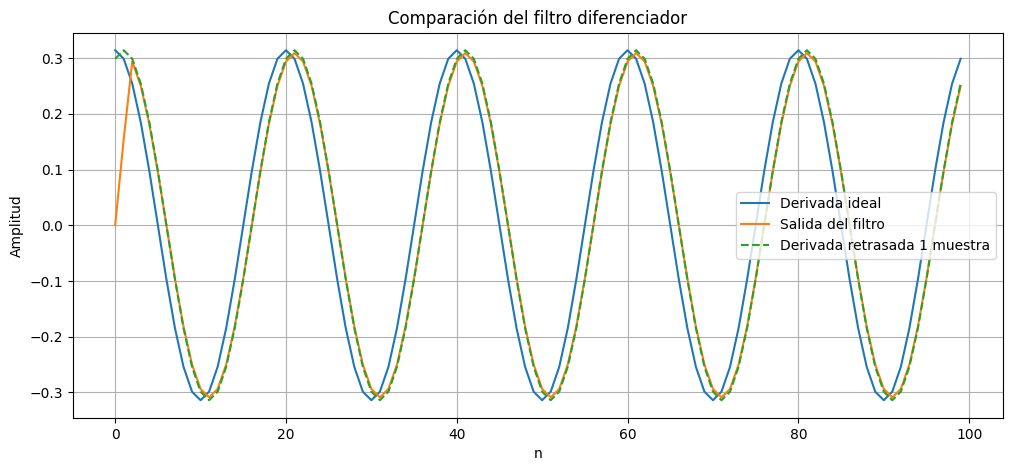

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter

# Señal
N = 100
n = np.arange(N)

Omega = 0.1 * np.pi
x = np.sin(Omega * n)

# Filtro diferenciador
# H(z) = (1 - z^-2)/2
b = [1/2, 0, -1/2]
a = [1]

y = lfilter(b, a, x)

# Derivada ideal
derivada = Omega * np.cos(Omega * n)

# Derivada ideal retrasada 1 muestra
derivada_retrasada = Omega * np.cos(Omega * (n - 1))

# Gráfico
plt.figure(figsize=(12,5))

plt.plot(n, derivada, label='Derivada ideal')
plt.plot(n, y, label='Salida del filtro')
plt.plot(n, derivada_retrasada, '--', label='Derivada retrasada 1 muestra')

plt.xlabel('n')
plt.ylabel('Amplitud')
plt.title('Comparación del filtro diferenciador')
plt.grid()
plt.legend()

plt.show()

Podemos observar que si comparamos la derivada con la respuesta del filtro la derivada no tiene retraso pero si la misma forma que la respuesta del filtro, pero si retrasamos la derivada una muestra la respuesta del filtro y la derivada son iguales.


Ceros: [-1.  1.]
Polos: [0. 0.]


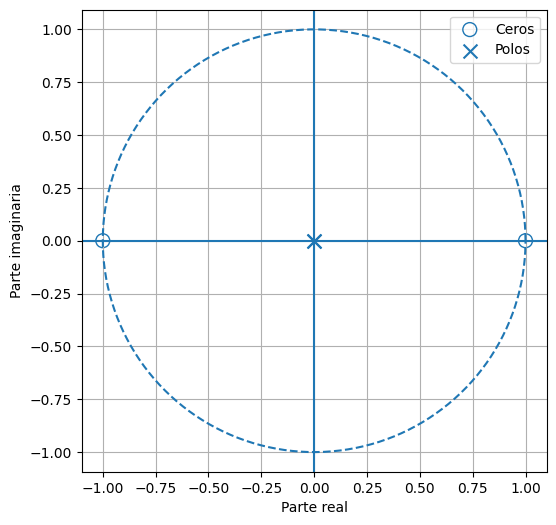

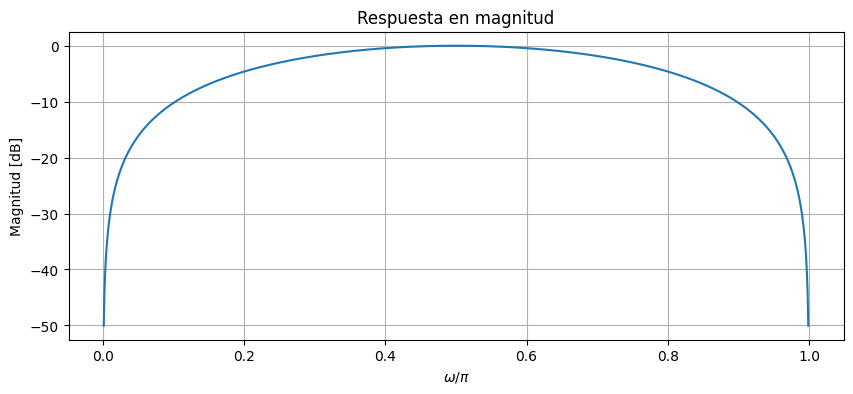

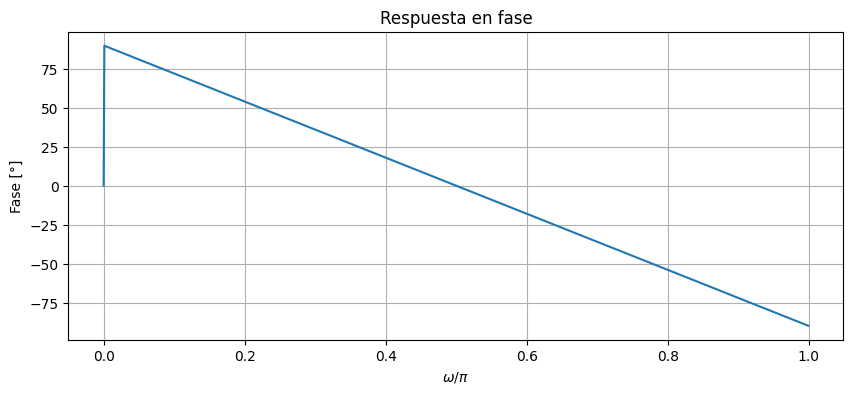

In [5]:
# H(z) = (1 - z^-2)/2

b=[1,0,-1]
a=[2,0,0]

polos_ceros(b,a)

# Sistema discreto
sistema = signal.dlti(b, a, dt=1)

# Bode discreto
w, mag, fase = signal.dbode(sistema, n=1000)

# Magnitud
plt.figure(figsize=(10,4))
plt.plot(w/np.pi, mag)
plt.xlabel(r'$\omega/\pi$')
plt.ylabel('Magnitud [dB]')
plt.title('Respuesta en magnitud')
plt.grid()
plt.show()

# Fase
plt.figure(figsize=(10,4))
plt.plot(w/np.pi, fase)
plt.xlabel(r'$\omega/\pi$')
plt.ylabel('Fase [°]')
plt.title('Respuesta en fase')
plt.grid()
plt.show()

## Diagrama en bloques

<div align="center">
    <img src="4.png" width="1000">
</div>


## Filtro elimina continua


Ceros: [1.]
Polos: [0.9]


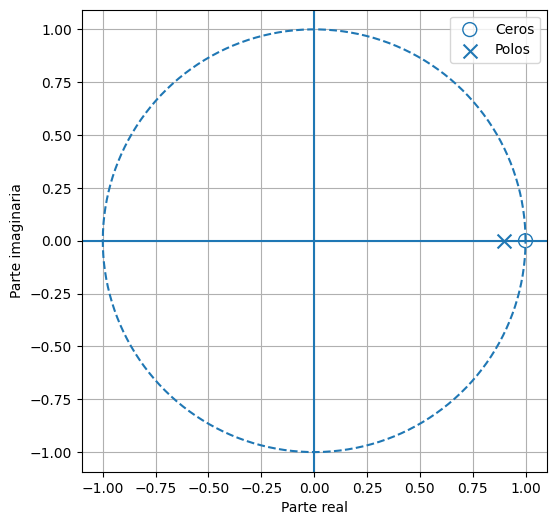

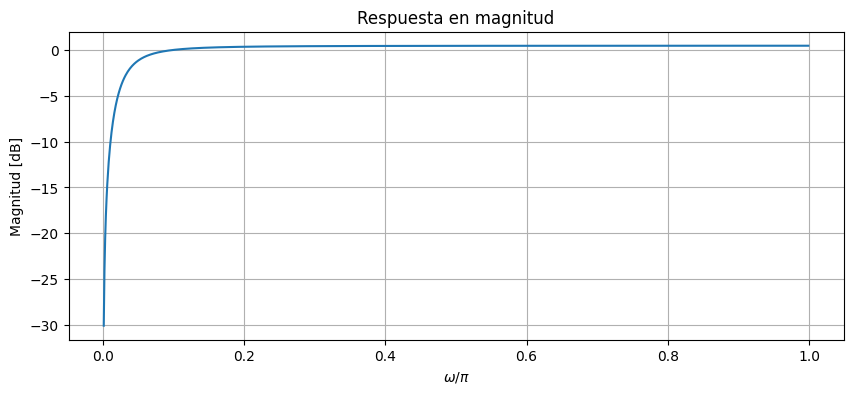

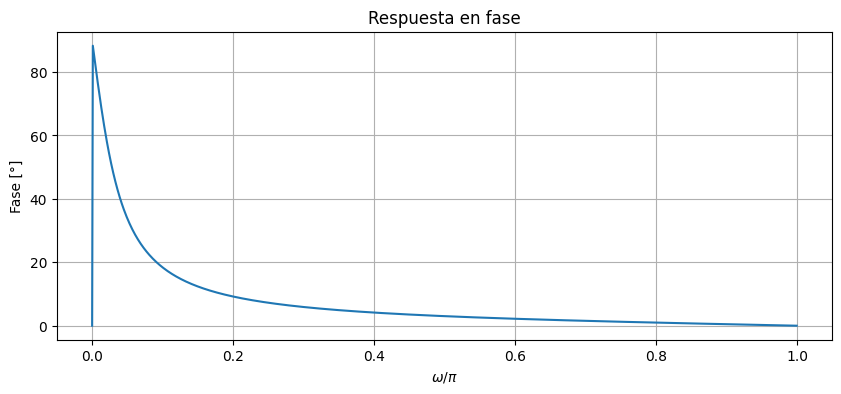

In [6]:
# H(z) = (1 - z^-1)/(1-0.9 z^-1)

b=[1,-1]
a=[1,-0.9]

polos_ceros(b,a)

# Sistema discreto
sistema = signal.dlti(b, a, dt=1)

# Bode discreto
w, mag, fase = signal.dbode(sistema, n=1000)

# Magnitud
plt.figure(figsize=(10,4))
plt.plot(w/np.pi, mag)
plt.xlabel(r'$\omega/\pi$')
plt.ylabel('Magnitud [dB]')
plt.title('Respuesta en magnitud')
plt.grid()
plt.show()

# Fase
plt.figure(figsize=(10,4))
plt.plot(w/np.pi, fase)
plt.xlabel(r'$\omega/\pi$')
plt.ylabel('Fase [°]')
plt.title('Respuesta en fase')
plt.grid()
plt.show()

## Diagrama en bloques

<div align="center">
    <img src="5.png" width="1000">
</div>

# Respuesta en frecuencia

Partimos de:

$$
H(z)=\frac{z-1}{z-\beta}
$$

Dividiendo numerador y denominador por $z$:

$$
H(z)=\frac{1-z^{-1}}{1-\beta z^{-1}}
$$

Evaluando sobre el círculo unitario, $z=e^{j\Omega}$:

$$
H(\Omega)
=
\frac{1-e^{-j\Omega}}
{1-\beta e^{-j\Omega}}
$$

Utilizando:

$$
e^{-j\Omega}=\cos\Omega-j\sin\Omega
$$

queda:

$$
H(\Omega)
=
\frac{
1-\cos\Omega+j\sin\Omega
}{
1-\beta\cos\Omega+j\beta\sin\Omega
}
$$

---

## Módulo de la respuesta en frecuencia

$$
|H(\Omega)|
=
\frac{
\sqrt{(1-\cos\Omega)^2+\sin^2\Omega}
}{
\sqrt{(1-\beta\cos\Omega)^2+\beta^2\sin^2\Omega}
}
$$

Desarrollando:

$$
(1-\cos\Omega)^2+\sin^2\Omega
=
1-2\cos\Omega+\cos^2\Omega+\sin^2\Omega
$$

Como:

$$
\cos^2\Omega+\sin^2\Omega=1
$$

resulta:

$$
\boxed{
|H(\Omega)|
=
\sqrt{
\frac{
2-2\cos\Omega
}{
1-2\beta\cos\Omega+\beta^2
}
}
}
$$

---

## Evaluación en $\Omega=\pi$

Como:

$$
\cos\pi=-1
$$

entonces:

$$
|H(\pi)|
=
\sqrt{
\frac{2-2\cos\pi}
{1-2\beta\cos\pi+\beta^2}
}
$$

$$
|H(\pi)|
=
\sqrt{
\frac{4}
{1+2\beta+\beta^2}
}
$$

Como:

$$
1+2\beta+\beta^2=(1+\beta)^2
$$

queda:

$$
\boxed{
|H(\pi)|=\frac{2}{|1+\beta|}
}
$$

Si se considera $\beta>-1$:

$$
\boxed{
|H(\pi)|=\frac{2}{1+\beta}
}
$$

---

## Condición a $\Omega=0.1\pi$

Si a $\Omega=0.1\pi$ la amplitud debe estar $3\,\text{dB}$ por debajo del valor en $\Omega=\pi$:

$$
20\log_{10}
\left(
\frac{|H(0.1\pi)|}{|H(\pi)|}
\right)
=-3
$$

Por lo tanto:

$$
\boxed{
|H(0.1\pi)|
=
10^{-3/20}|H(\pi)|
}
$$

#### En python hago el desarrollo

In [7]:
import numpy as np
from scipy.optimize import brentq

def modulo_H(beta, omega):
    b = [1, -1]
    a = [1, -beta]

    _, H = signal.freqz(b, a, worN=[omega])

    return np.abs(H[0])

omega1 = 0.1*np.pi
omega2 = np.pi

objetivo = 10**(-3/20)

def ecuacion(beta):
    return modulo_H(beta, omega1) / modulo_H(beta, omega2) - objetivo

beta_sol = brentq(ecuacion, 0, 0.999)

print("Beta =", beta_sol)

Beta = 0.7271025813887385


## Filtro Peine


Ceros: [-0.92387953+0.38268343j -0.92387953-0.38268343j -0.38268343+0.92387953j
 -0.38268343-0.92387953j  0.38268343+0.92387953j  0.38268343-0.92387953j
  0.92387953+0.38268343j  0.92387953-0.38268343j]
Polos: [0. 0. 0. 0. 0. 0. 0. 0.]


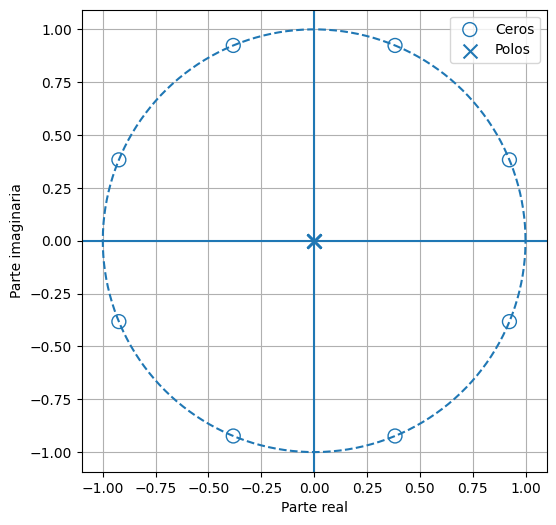

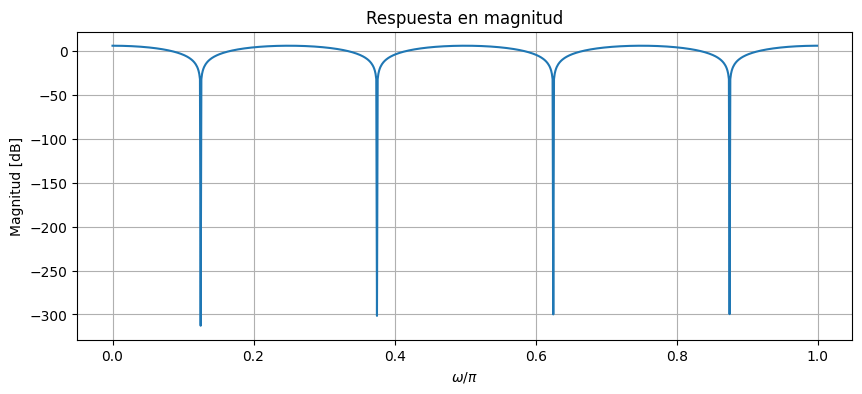

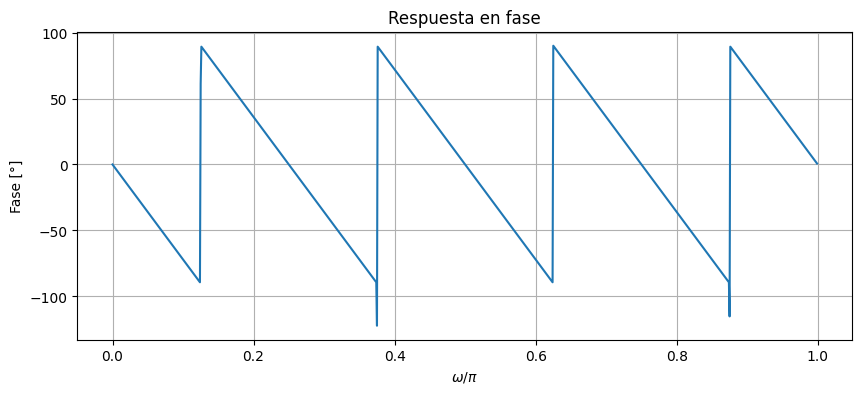

In [16]:
# H(z) = (1 + z^-8)

b=[1, 0, 0, 0, 0, 0, 0, 0, 1]
a=[1, 0, 0, 0, 0, 0, 0, 0, 0]

polos_ceros(b,a)

# Sistema discreto
sistema = signal.dlti(b, a, dt=1)

# Bode discreto
w, mag, fase = signal.dbode(sistema, n=1000)

# Magnitud
plt.figure(figsize=(10,4))
plt.plot(w/np.pi, mag)
plt.xlabel(r'$\omega/\pi$')
plt.ylabel('Magnitud [dB]')
plt.title('Respuesta en magnitud')
plt.grid()
plt.show()

# Fase
fase_wrapped = (fase + 180) % 360 - 180

plt.figure(figsize=(10,4))
plt.plot(w/np.pi, fase_wrapped)
plt.xlabel(r'$\omega/\pi$')
plt.ylabel('Fase [°]')
plt.title('Respuesta en fase')
plt.grid()
plt.show()

<div align="center">
    <img src="6.png" width="1000">
</div>

# Cálculo de picos y nulos

Partimos de la función transferencia:

$$
T(z)=1+z^{-8}
$$

Evaluando sobre el círculo unitario:

$$
z=e^{j\Omega}
$$

se obtiene:

$$
T(e^{j\Omega})=1+e^{-j8\Omega}
$$

Utilizando la identidad:

$$
1+e^{-j8\Omega}
=
2e^{-j4\Omega}\cos(4\Omega)
$$

queda:

$$
\boxed{
T(e^{j\Omega})=
2e^{-j4\Omega}\cos(4\Omega)
}
$$

Por lo tanto, su módulo es:

$$
\boxed{
|T(e^{j\Omega})|
=
2|\cos(4\Omega)|
}
$$

---

## Frecuencias de los picos

Los picos aparecen cuando:

$$
|\cos(4\Omega)|=1
$$

Esto ocurre cuando:

$$
4\Omega=k\pi
$$

por lo tanto:

$$
\boxed{
\Omega=\frac{k\pi}{4}
}
$$

Considerando solamente el intervalo:

$$
0\leq\Omega\leq\pi
$$

los picos se encuentran en:

$$
\Omega=
0,\;
\frac{\pi}{4},\;
\frac{\pi}{2},\;
\frac{3\pi}{4},\;
\pi
$$

---

### Conversión a frecuencia

Usando:

$$
\Omega=\pi
\quad\longleftrightarrow\quad
f=\frac{F_s}{2}
$$

se puede convertir mediante:

$$
\boxed{
f=
\frac{\Omega}{\pi}\frac{F_s}{2}
}
$$

Para:

$$
F_s=1000\text{ Hz}
$$

resulta:

$$
f_1=0\text{ Hz}
$$

$$
f_2=
\frac{\pi/4}{\pi}\frac{1000}{2}
=
125\text{ Hz}
$$

$$
f_3=
\frac{\pi/2}{\pi}\frac{1000}{2}
=
250\text{ Hz}
$$

$$
f_4=
\frac{3\pi/4}{\pi}\frac{1000}{2}
=
375\text{ Hz}
$$

$$
f_5=
\frac{\pi}{\pi}\frac{1000}{2}
=
500\text{ Hz}
$$

Por lo tanto:

$$
\boxed{
f_{\text{picos}}
=
\{0,\;125,\;250,\;375,\;500\}\text{ Hz}
}
$$

---

## Frecuencias de los nulos

Los nulos aparecen cuando:

$$
\cos(4\Omega)=0
$$

El coseno se anula para:

$$
4\Omega=
\frac{(2k+1)\pi}{2}
$$

por lo tanto:

$$
\boxed{
\Omega=
\frac{(2k+1)\pi}{8}
}
$$

Dentro del intervalo:

$$
0\leq\Omega\leq\pi
$$

los nulos están en:

$$
\Omega=
\frac{\pi}{8},
\frac{3\pi}{8},
\frac{5\pi}{8},
\frac{7\pi}{8}
$$

Con $F_s=1000\text{ Hz}$:

$$
f_1=
\frac{\pi/8}{\pi}\frac{1000}{2}
=
62.5\text{ Hz}
$$

$$
f_2=
\frac{3\pi/8}{\pi}\frac{1000}{2}
=
187.5\text{ Hz}
$$

$$
f_3=
\frac{5\pi/8}{\pi}\frac{1000}{2}
=
312.5\text{ Hz}
$$

$$
f_4=
\frac{7\pi/8}{\pi}\frac{1000}{2}
=
437.5\text{ Hz}
$$

Por lo tanto:

$$
\boxed{
f_{\text{nulos}}
=
\{62.5,\;187.5,\;312.5,\;437.5\}\text{ Hz}
}
$$